In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sn
import numpy as np
import pandas as pd
import math
import datetime
import platform

import os
for dirname, _, filenames in os.walk(r'C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\02_d_Desafío_-_Procesamiento_y_redes_recurrentes__Parte_I_.pdf
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\Apoyo Desafío - Procesamiento y redes recurrentes (Parte I).zip
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\sample_submission.csv
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\test.csv
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\test.csv.zip
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\train.csv
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\train.csv.zip
C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\Tutoría - Procesamiento y redes recurrent

In [2]:
# Extensión de tensorboard para notebook
%load_ext tensorboard

In [3]:
train = pd.read_csv(r'C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\train.csv')
test = pd.read_csv(r'C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\6. 06-11-2024\test.csv')

In [4]:
train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
train.info(),train.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


(None, (42000, 785))

In [6]:
X = train.iloc[:, 1:785]
y = train.iloc[:, 0]

X_test = test.iloc[:, 0:784]

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_validation, y_train, y_validation = train_test_split(X, y, test_size = 0.2,random_state = 1212)

Reestructurado de los datos para que tengan la forma adecuada para trabajar con modelos que usan imágenes (Redes Neuronales Convolucionales)

- Los dataframes los convertimos a arreglos de NumPy y los restructuramos para que cada imagen tenga la forma (28x28), lo cual es fundamental que tengan este formato para el procesamiento de imágenes.

In [8]:
# Reshape
x_train_re = X_train.to_numpy().reshape(33600, 28, 28)
y_train_re = y_train.values
x_validation_re = X_validation.to_numpy().reshape(8400, 28, 28)
y_validation_re = y_validation.values
x_test_re = test.to_numpy().reshape(28000, 28, 28)

In [12]:
x_train_re[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   2,  56, 140, 195, 155, 155,  12,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         30, 192, 254, 254, 254, 254, 254, 103,   0,   0,   0,   0,   0,
          0,   0],
       [  

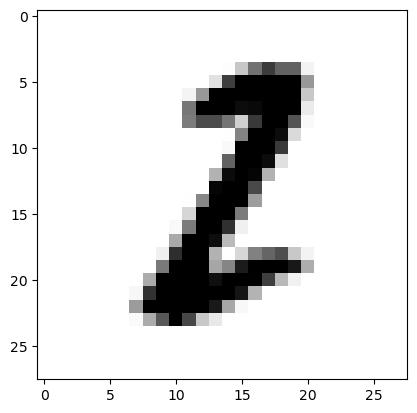

In [13]:
# Revisión de cualquier número
plt.imshow(x_train_re[0], cmap=plt.cm.binary)
plt.show()

- numbers_to_display -> definicion del numero de imagenes a mostrar
- num_cells = math.ceil(math.sqrt(numbers_to_display)) -> calculo del tamano de la cuadricula
- for i in range(numbers_to_display): -> bucle para graficar cada imagen

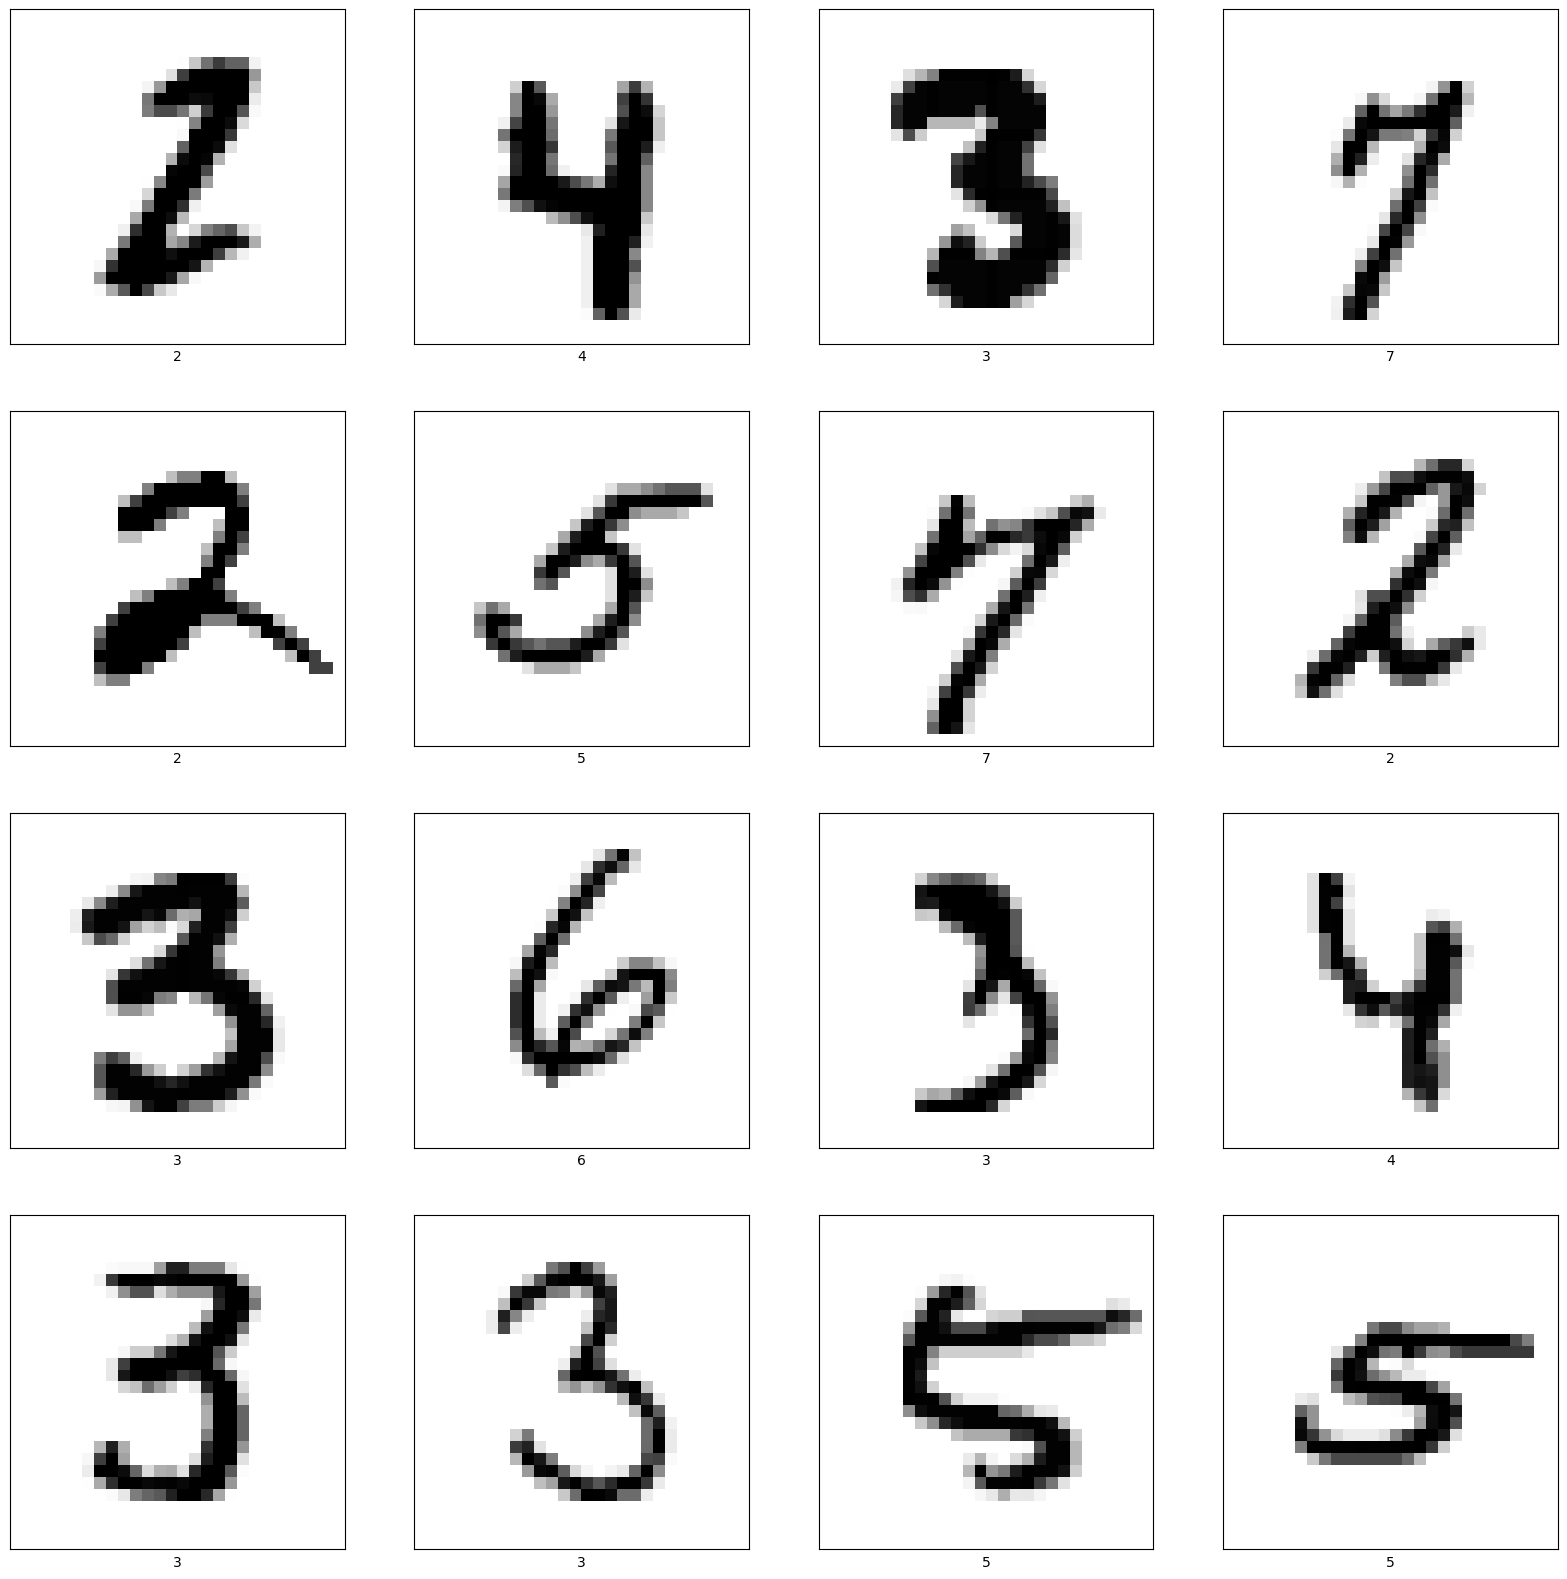

In [15]:
numbers_to_display = 16
num_cells = math.ceil(math.sqrt(numbers_to_display))
plt.figure(figsize=(20,20))
for i in range(numbers_to_display):
    plt.subplot(num_cells, num_cells, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train_re[i], cmap=plt.cm.binary)
    plt.xlabel(y_train_re[i])
plt.show()

In [16]:
(_, IMAGE_WIDTH, IMAGE_HEIGHT) = x_train_re.shape
IMAGE_CHANNELS = 1                                       # establece que vamos a trabajar con imagenes con escala de grises

In [18]:
x_train_with_chanels = x_train_re.reshape(
    x_train_re.shape[0],
    IMAGE_WIDTH,
    IMAGE_HEIGHT,
    IMAGE_CHANNELS
)

x_validation_with_chanels = x_validation_re.reshape(
    x_validation_re.shape[0],
    IMAGE_WIDTH,
    IMAGE_HEIGHT,
    IMAGE_CHANNELS
)

x_test_with_chanels = x_test_re.reshape(
    x_test_re.shape[0],
    IMAGE_WIDTH,
    IMAGE_HEIGHT,
    IMAGE_CHANNELS
)

##### Normalizacion de imagenes

In [20]:
x_train_normalized = x_train_with_chanels / 255
x_validation_normalized = x_validation_with_chanels / 255
x_test_normalized = x_test_with_chanels / 255

Modelo

Este código construye un modelo de red neuronal convolucional (CNN) usando la API secuencial de Keras en TensorFlow. Cada capa se agrega de forma secuencial para procesar imágenes y clasificarlas en 10 categorías.

In [23]:
model = tf.keras.models.Sequential()

model.add(tf.keras.layers.Convolution2D(
    input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, IMAGE_CHANNELS),      # Define las dimensiones de las imágenes de entrada (ancho, alto y canales).
    kernel_size=5,                                                # Indica que los filtros de convolución tendrán un tamaño de 5x5 píxeles.
    filters=8,                                                    # La capa aplicará 8 filtros, lo que significa que se extraerán 8 conjuntos de características.
    strides=1,                                                    # La convolución se moverá un píxel a la vez.
    activation=tf.keras.activations.relu,                         # Se utiliza la función de activación ReLU para introducir no linealidad.
    kernel_initializer=tf.keras.initializers.VarianceScaling()    # Inicializa los pesos de forma que se mantenga la varianza adecuada.
))


model.add(tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),                                              # Reduce la dimensión de la salida dividiéndola en bloques de 2x2.
    strides=(2, 2)                                                 # Mueve la ventana de pooling 2 píxeles a la vez, lo que reduce
))                                                                 # a la mitad tanto el ancho como la altura.


model.add(tf.keras.layers.Convolution2D(                           # No se especifica input_shape ya que ya se conoce la forma
    kernel_size=5,                                                 # de salida de la capa anterior.
    filters=16,                                                    # filters=16: Se extraen más características al aumentar el número de filtros.
    strides=1,
    activation=tf.keras.activations.relu,
    kernel_initializer=tf.keras.initializers.VarianceScaling()
))

model.add(tf.keras.layers.MaxPooling2D(                            # segunda capa de maxpooling: Se realiza otro muestreo máximo para reducir aún más
    pool_size=(2, 2),                                              # la dimensionalidad de las características extraídas
    strides=(2, 2)
))

model.add(tf.keras.layers.Flatten())                               # convierte la salida multidimensional de las capas anteriores en un vector
                                                                   # unidimensional, necesario para las capas densas (fully connected)
              
model.add(tf.keras.layers.Dense(                                   # Crea una capa con 128 neuronas
    units=128,                                                     # Se utiliza la activación ReLU para introducir no linealidad y
    activation=tf.keras.activations.relu                           # permitir que el modelo aprenda relaciones complejas.
));


model.add(tf.keras.layers.Dropout(0.2))                            # Aplicamos la técnica de Dropout, lo cual descarta aleatoriamente el 20%
                                                                   # de las neuronas durante el entrenamiento.

model.add(tf.keras.layers.Dense(                                   # capa de salida
    units=10,                                                      # La capa tiene 10 neuronas, cada una correspondiente a una clase
    activation=tf.keras.activations.softmax,                       # (por ejemplo, dígitos del 0 al 9 en el caso de MNIST).
    kernel_initializer=tf.keras.initializers.VarianceScaling()     # La función de activación softmax convierte las salidas en una
))                                                                 # distribución de probabilidades, facilitando la clasificación.


In [24]:
# Revisión del modelo
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 24, 24, 8)         208       
                                                                 
 max_pooling2d (MaxPooling2  (None, 12, 12, 8)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 8, 8, 16)          3216      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 4, 4, 16)          0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 256)               0         
                                                                 
 dense (Dense)               (None, 128)               3

##### Configuramos el proceso de entrenamiento del modelo:
- Definiendo el optimizador
- La función de pérdida
- Métricas que se usarán para evaluar el desempeño

In [25]:
adam_optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)           # creamos una instancia del optimizador Adam

# compilacion del modelo
model.compile(
    optimizer=adam_optimizer,                                            # se le indica al modelo que use el optimizador de Adam que se configuro
    loss=tf.keras.losses.sparse_categorical_crossentropy,                # anteriormente para ajustar sus pesos.
    metrics=['accuracy']                                                 # definimos una funcion de perdida para problemas de clasificacion multiclase
)                                                                        # cuando las etiquetas están representadas como enteros (por ejemplo,
                                                                         # en la clasificación de dígitos del 0 al 9).
                                                                         # la función de perdida calcula la diferencia entre la distribución de
                                                                         # probabilidad predicha por el modelo y la distribución verdadera.

                                                                         # metrics=['accuracy']
                                                                         # Se especifica que, durante el entrenamiento y la evaluación, se medirá
                                                                         # la precisión (accuracy) del modelo.
                                                                         # Esto ayuda a entender qué tan bien está clasificando el modelo los ejemplos.

Entrenamiento

##### Este código se encarga de lo siguiente:

- configurar el registro de información para TensorBoard
- entrenar el modelo
- Y, finalmente, notificar que el entrenamiento ha finalizado.

##### Explicación del código

```python
log_dir=".logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
```
- Se crea una cadena (log_dir) que indica dónde se almacenarán los registros del entrenamiento.
- datetime.datetime.now().strftime("%Y%m%d-%H%M%S") genera una marca de tiempo con el formato año, mes, día, hora, minuto y segundo. Esto asegura que cada ejecución tenga un directorio único, facilitando la organización de los registros.


```python
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
```
Creación de callback para TensorBoard
- Se instancia un callback de TensorBoard que utilizará el directorio definido para guardar la información.
- El parámetro `histogram_freq=1` indica que se calcularán y registrarán histogramas de los pesos del modelo cada época, lo que ayuda a visualizar cómo evolucionan durante el entrenamiento.

- El objeto `training_history` almacena los valores de pérdida y precisión para cada época, permitiendo analizar la evolución del entrenamiento

In [26]:
log_dir=".logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)


epocas = 10                                                                       # Establecemos que el entranamiento se realizará durante
                                                                                  # 10 épocas (iteraciones sobre todo el conjunto de datos).

training_history = model.fit(                                                     
    x_train_normalized,                                                           # Datos de entrenamiento: Se usan x_train_normalized y y_train_re                                                         
    y_train_re,                
    epochs=epocas,                                                                # Épocas: Se entrena el modelo durante 10 épocas.
    validation_data=(x_validation_normalized, y_validation_re),                   # Validación: Se proporciona un conjunto de validación
    callbacks=[tensorboard_callback]                                              # (x_validation_normalized, y_validation_re) para evaluar
)                                                                                 # el rendimiento del modelo en cada época.
                                                                                  # Callbacks: Se pasa el tensorboard_callback para que durante el
                                                                                  # entrenamiento se registren los datos necesarios para su
print("Modelo entrenado")                                                         # visualización en TensorBoard.

Epoch 1/10


1050/1050 [==============================] - 6s 5ms/step - loss: 0.2786 - accuracy: 0.9121 - val_loss: 0.0885 - val_accuracy: 0.9731
Epoch 2/10
1050/1050 [==============================] - 5s 5ms/step - loss: 0.0924 - accuracy: 0.9723 - val_loss: 0.0626 - val_accuracy: 0.9821
Epoch 3/10
1050/1050 [==============================] - 5s 5ms/step - loss: 0.0625 - accuracy: 0.9797 - val_loss: 0.0483 - val_accuracy: 0.9860
Epoch 4/10
1050/1050 [==============================] - 5s 5ms/step - loss: 0.0503 - accuracy: 0.9841 - val_loss: 0.0558 - val_accuracy: 0.9837
Epoch 5/10
1050/1050 [==============================] - 5s 5ms/step - loss: 0.0429 - accuracy: 0.9862 - val_loss: 0.0534 - val_accuracy: 0.9856
Epoch 6/10
1050/1050 [==============================] - 5s 4ms/step - loss: 0.0357 - accuracy: 0.9882 - val_loss: 0.0447 - val_accuracy: 0.9863
Epoch 7/10
1050/1050 [==============================] - 5s 4ms/step - loss: 0.0298 - accuracy: 0.9908 - val_loss: 0.0470 - val_accurac

##### Visualización del aprendizaje

Creamos una gráfica para visualizar cómo evolucionó la pérdida (loss) durante el entranamiento del modelo

```python
plt.plot(training_history.history['loss'], label='Entrenamiento')
```
- curva que muestra la evolución de la pérdida (loss) del conjunto de entrenamiento a lo largo de las épocas

```python
plt.plot(training_history.history['val_loss'], label='Validación')
```
-  curva que muestra la evolución de la pérdida (loss) del conjunto de validación a lo largo de las épocas.

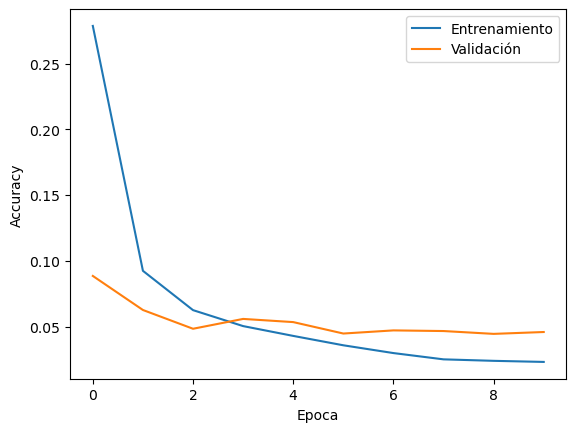

In [27]:
plt.xlabel('Epoca')
plt.ylabel('Loss')
plt.plot(training_history.history['loss'], label='Entrenamiento')
plt.plot(training_history.history['val_loss'], label='Validación')
plt.legend()

```python
plt.plot(training_history.history['accuracy'], label='Entrenamiento')
```
- Dibujamos una linea que muestra cómo evoluciona la precisión del modelo en los datos de entrenamiento a lo largo de las épocas

```python
plt.plot(training_history.history['val_accuracy'], label='Validación')
```
-   Dibujamos una línea que muestra cómo evoluciona la precisión del modelo en los datos de validación a lo largo de las épocas

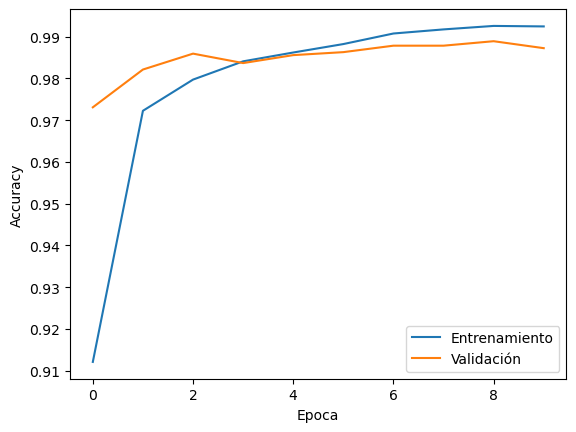

In [28]:
plt.xlabel('Epoca')
plt.ylabel('Accuracy')
plt.plot(training_history.history['accuracy'], label='Entrenamiento')
plt.plot(training_history.history['val_accuracy'], label='Validación')
plt.legend()   # se añade una leyenda para distinguir fácilmente ambas líneas

La gráfica anterior nos permite visualizar lo siguiente:

- El rendimiento del modelo a lo largo del tiempo (las épocas)
- Comparar cómo se comporta con datos que ha visto (entrenamiento) vs. datos nuevos (validación)
- Detectar problemas como sobreajuste (si la línea de entrenamiento sube mucho pero la de validación no)

##### Explicacion de predicitions

- Le pasa los datos de validación normalizados (x_validation_normalized) como entrada - estos son datos que el modelo no utilizó durante el entrenamiento
- Guarda las predicciones resultantes en la variable predictions

El resultado (predictions) será un array con las salidas del modelo para cada ejemplo en tu conjunto de validación. Dependiendo del tipo de modelo:
- Para clasificación: serán probabilidades para cada clase o la clase predicha
- Para regresión: serán valores numéricos predichos

##### Este paso es crucial para evaluar el rendimiento del modelo con datos que no ha visto durante el entrenamiento, lo que te da una idea más realista de cómo funcionará el modelo con datos nuevos en el futuro.

In [29]:
predictions = model.predict([x_validation_normalized])

263/263 [==============================] - 1s 2ms/step


In [30]:
pd.DataFrame(predictions)

,0,1,2,3,4,5,6,7,8,9
0,9.905989e-09,9.999998e-01,2.136846e-07,1.605104e-11,3.377291e-10,3.017031e-10,1.503211e-08,4.929816e-09,5.457706e-08,1.159593e-08
1,8.417461e-14,2.104370e-07,3.370509e-09,9.999422e-01,2.252789e-12,5.705306e-05,9.996233e-13,6.905096e-08,4.766816e-09,4.820619e-07
2,3.047613e-10,8.590049e-09,4.507488e-08,2.676277e-05,1.266731e-11,3.096565e-05,2.192003e-08,5.011035e-10,9.999418e-01,3.495881e-07
3,1.442172e-08,9.999951e-01,2.489831e-06,3.185964e-08,6.308015e-07,1.175741e-08,9.676180e-08,1.356467e-06,2.447515e-07,1.771515e-08
4,1.738921e-14,3.386430e-14,2.728608e-11,9.442411e-09,1.353509e-05,6.106648e-10,2.735602e-14,1.221864e-08,2.140973e-06,9.999843e-01
...,...,...,...,...,...,...,...,...,...,...
8395,1.562662e-17,3.235622e-15,2.274959e-12,5.431363e-19,1.000000e+00,4.297220e-14,5.338433e-12,4.268986e-18,7.715675e-17,4.892560e-14
8396,2.961656e-10,4.538087e-12,4.140051e-13,4.430985e-08,5.225897e-12,9.995455e-01,4.497716e-04,7.572651e-15,4.726498e-06,3.562561e-09
8397,4.308736e-11,2.072615e-07,3.377687e-10,7.709851e-10,5.780281e-06,3.825069e-11,1.668557e-12,9.999872e-01,1.236332e-09,6.666240e-06
8398,3.159808e-09,1.714064e-12,1.417850e-11,4.455215e-11,4.676998e-13,6.555686e-07,9.999994e-01,3.424474e-17,4.230589e-09,2.114401e-14


In [31]:
# Dejamos la predicción con máxima probabilidad
predictions = np.argmax(predictions, axis=1)
pd.DataFrame(predictions)

,0
0,1
1,3
2,8
3,1
4,9
...,...
8395,4
8396,5
8397,7
8398,6


El código sirve para verificar la precisión del modelo comparando la predicción con la imagen real

```python
print(predictions[i])
```
- Esta instrucción muestra la clase predicha para la imagen seleccionada. El valor mostrado será un número entero entre 0 y 9, correspondiente al dígito que el modelo ha identificado en la imagen.

```python
plt.imshow(x_validation_normalized[i].reshape((IMAGE_WIDTH, IMAGE_HEIGHT)), cmap=plt.cm.binary)
```
Explicación:
- Accede a la imagen normalizada en la posición 60 del conjunto de validación
- Reestructura la imagen a sus dimensiones originales (28×28 píxeles, eliminando la dimensión del canal)
- Utiliza la función imshow() de Matplotlib para representar la imagen
- Establece un esquema de color binario (blanco y negro) mediante cmap=plt.cm.binary, apropiado para imágenes de dígitos manuscritos


8


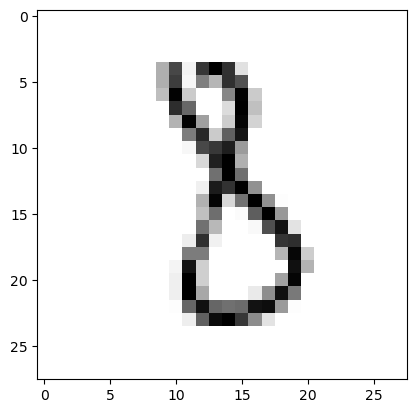

In [43]:
i = 60
print(predictions[i])
plt.imshow(x_validation_normalized[i].reshape((IMAGE_WIDTH, IMAGE_HEIGHT)), cmap=plt.cm.binary)
plt.show()